# EDA of simulated normal behaviour 

Explores `data/normal.parquet` (28 days, 12 cells, 1-minute steps, seed 42), made with `cellpulse-simulate`.
Goal: check the simulator produces realistic, consistent normal data before faults and detectors are built on top of it.

In [30]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.dpi"] = 60

df = pd.read_parquet("../data/normal.parquet")

### 1. Table checks

In [31]:
df.head()

,cell_id,observed_at,dl_throughput_mbps,ul_throughput_mbps,prb_utilisation_pct,latency_ms,active_ues,call_drop_rate_pct,rrc_success_rate_pct,sinr_db
0,site-a/cell-001,2026-01-05 00:00:00+00:00,73.595600,37.494394,28.878739,5.250650,43,0.334262,99.675481,14.370884
1,site-a/cell-001,2026-01-05 00:01:00+00:00,81.406600,43.289388,26.038666,5.177451,39,0.395162,99.622987,13.788057
2,site-a/cell-001,2026-01-05 00:02:00+00:00,80.818905,39.664552,23.590846,5.095570,36,0.339399,99.434362,12.766700
3,site-a/cell-001,2026-01-05 00:03:00+00:00,80.396222,42.364433,24.250731,5.038890,36,0.310371,99.464095,13.116615
4,site-a/cell-001,2026-01-05 00:04:00+00:00,79.275120,39.152170,23.913379,5.157021,36,0.287297,99.462679,12.886029


In [32]:
df.shape

(483840, 10)

In [33]:
df.dtypes

cell_id                                 str
observed_at             datetime64[us, UTC]
dl_throughput_mbps                  float64
ul_throughput_mbps                  float64
prb_utilisation_pct                 float64
latency_ms                          float64
active_ues                           uint32
call_drop_rate_pct                  float64
rrc_success_rate_pct                float64
sinr_db                             float64
dtype: object

In [34]:
df.isna().sum()

cell_id                 0
observed_at             0
dl_throughput_mbps      0
ul_throughput_mbps      0
prb_utilisation_pct     0
latency_ms              0
active_ues              0
call_drop_rate_pct      0
rrc_success_rate_pct    0
sinr_db                 0
dtype: int64

In [35]:
df["cell_id"].value_counts()

cell_id
site-a/cell-001    40320
site-a/cell-002    40320
site-a/cell-003    40320
site-a/cell-004    40320
site-b/cell-001    40320
site-b/cell-002    40320
site-b/cell-003    40320
site-b/cell-004    40320
site-c/cell-001    40320
site-c/cell-002    40320
site-c/cell-003    40320
site-c/cell-004    40320
Name: count, dtype: int64

In [36]:
df["observed_at"].min(), df["observed_at"].max()

(Timestamp('2026-01-05 00:00:00+0000', tz='UTC'),
 Timestamp('2026-02-01 23:59:00+0000', tz='UTC'))

In [37]:
df.groupby("cell_id")["observed_at"].diff().value_counts(dropna=False)

observed_at
0 days 00:01:00    483828
NaT                    12
Name: count, dtype: int64

**Findings, section 1:**
- Rows and columns: 483,840 rows × 10 columns
- Missing values: 0 missing values 
- Rows per cell: 40,320 for every cell = 1,440 × 28
- Time range: Mon 5 Jan 2026 00:00 UTC to Sun 1 Feb 2026 23:59 UTC, exactly 4 full weeks
- Gaps between time steps (and why there are some NaT): 483,828 gaps of exactly 1 minute and 12 NaT. The NaT values are the first row of each cell (no earlier row to subtract from), so 12 cells → 12 NaT. No minutes are missing.

### 2. Value ranges vs the expected range
| KPI | Expected range |
|---|---|
| prb_utilisation_pct | typical 50–70 %; above 80 % approaching capacity |
| dl_throughput_mbps | target 100 Mbps; falls as the cell gets busier |
| ul_throughput_mbps | target 50 Mbps; lower than download |
| latency_ms | about 1–20 ms |
| call_drop_rate_pct | below 2 % |
| rrc_success_rate_pct | above 98 % |
| sinr_db | about −10 to 30+ dB |
| active_ues | no universal range; low at night, high at peak |

In [38]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
dl_throughput_mbps,483840.0,75.17,12.38,31.43,67.34,76.37,85.07,106.39
ul_throughput_mbps,483840.0,37.59,6.19,15.67,33.66,38.19,42.54,53.30
prb_utilisation_pct,483840.0,32.93,13.73,4.92,21.42,31.48,41.51,83.16
latency_ms,483840.0,5.40,0.75,4.31,5.01,5.17,5.45,12.69
active_ues,483840.0,67.28,35.87,0.00,39.00,61.00,88.00,209.00
call_drop_rate_pct,483840.0,0.30,0.05,0.07,0.27,0.30,0.33,0.54
rrc_success_rate_pct,483840.0,99.50,0.10,99.04,99.43,99.50,99.57,99.97
sinr_db,483840.0,14.93,2.61,4.90,13.13,14.77,16.60,26.08


**Findings, section 2:**
- KPIs outside (or at the edge of) their range, and is that a problem?

1. Throughput above 100 / 50 Mbps: The formula can never exceed 100 but the ±3% measurement noise is due to the fact noise is applied AFTER the formula. Which is why max excedes our expected 100mbps. 

2. PRB above 80 %: only 29 of 483,840 rows, all in the busiest evening minutes. The drifting noise on the load pushes an already busy cell even busier for a while. Realistically the cell occasionally gets close to capacity at peak. Load stays just under 0.85, so call drops and RRC failures never start 

3. 0 users at night: the night baseline is 0.12 and a quiet cell (busyness near 0.8) has a night load of only about 0.10. The drifting noise very occasionally drags it close to 0, and round(load × max_ues) then rounds down to 0. Rare: only 30 rows with ≤3 users. Note that active_ues is the only KPI without its own measurement noise, so it follows load exactly.

4. Inside their expected range: latency (4.3–12.7 ms, within 1–20), call drop (max 0.54 %, below 2 %), RRC success (min 99.04 %, above 98 %), SINR (4.9–26.1 dB, within −10 to 30). PRB averages 33 %, below the typical 50–70 %, because the expected range describes busy hour but the also mean includes nights. At the weekday evening peak the average is ~60 %, inside the range.


### 3. Daily and weekly pattern

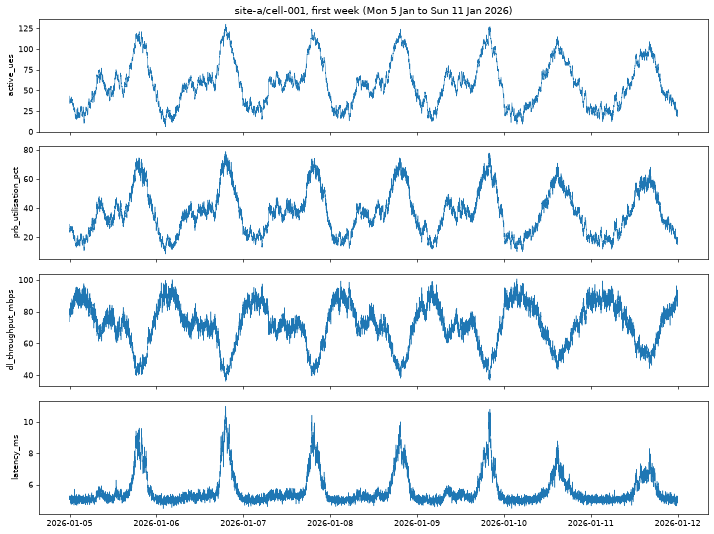

In [39]:
cell = df[df["cell_id"] == "site-a/cell-001"]
week = cell[cell["observed_at"] < "2026-01-12"]

kpis = ["active_ues", "prb_utilisation_pct", "dl_throughput_mbps", "latency_ms"]
fig, axes = plt.subplots(len(kpis), 1, figsize=(12, 9), sharex=True)
for ax, kpi in zip(axes, kpis, strict=True):
    ax.plot(week["observed_at"], week[kpi], linewidth=0.6)
    ax.set_ylabel(kpi)
axes[0].set_title("site-a/cell-001, first week (Mon 5 Jan to Sun 11 Jan 2026)")
fig.tight_layout()
plt.show()

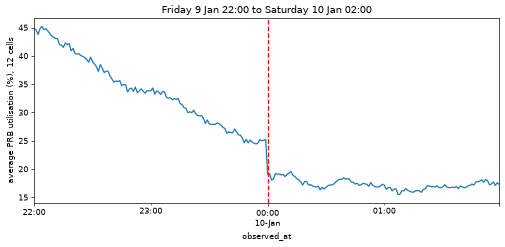

In [40]:
window = df[(df["observed_at"] >= "2026-01-09 22:00") & (df["observed_at"] < "2026-01-10 02:00")]
avg = window.groupby("observed_at")["prb_utilisation_pct"].mean()

ax = avg.plot(figsize=(10, 4))
ax.axvline(pd.Timestamp("2026-01-10 00:00", tz="UTC"), color="red", linestyle="--")
ax.set_ylabel("average PRB utilisation (%), 12 cells")
ax.set_title("Friday 9 Jan 22:00 to Saturday 10 Jan 02:00")
plt.show()

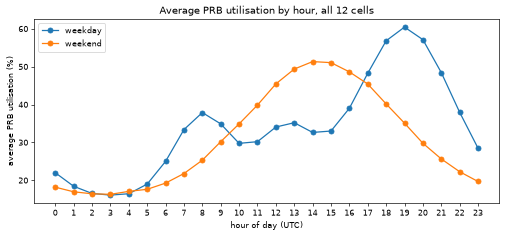

In [41]:
hour = df["observed_at"].dt.hour.rename("hour")
weekend = (df["observed_at"].dt.day_of_week >= 5).rename("weekend")

hourly = df.groupby([weekend, hour])["prb_utilisation_pct"].mean().unstack("weekend")
hourly.columns = ["weekday", "weekend"]

ax = hourly.plot(figsize=(10, 4), marker="o")
ax.set_xlabel("hour of day (UTC)")
ax.set_ylabel("average PRB utilisation (%)")
ax.set_title("Average PRB utilisation by hour, all 12 cells")
ax.set_xticks(range(24))
plt.show()

**Findings, section 3:**
- Does each KPI move the way the design says (direction and shape)? 
Yes. Users and PRB rise and fall together, throughput is their mirror image (high at night, low at peak), and latency stays flat at ~5 ms and only spikes at the evening peaks

- Weekday: Where are the peaks, how big are they, and do they match the bumps choosen (08:30, 13:00, 19:30)?
Three peaks. Morning around 08–09 (avg PRB ~38 %), lunch around 13 (~35 %), and the big evening peak at 19 (~60 %). They match the bumps (08:30, 13:00, 19:30), and the evening is the largest as designed

- Weekend vs weekday: The weekend has one broad, smooth peak around 14–15 (~51 % PRB), lower than the weekday evening peak, with no morning commute. Matches the single 15:00 bump

- Midnight: Within each day type the curve joins smoothly (weekday 28.5 → 22.0 → 18.4 across 23 → 0 → 1), so the midnight fix works. But the zoom plot shows a jump where weekday turns into weekend: average PRB drops from ~25 % to ~19 % in one minute at Sat 00:00 (and jumps up at Mon 00:00), because the simulator switches from the weekday curve to the weekend curve instantly. A detector could flag this as an anomaly every weekend. Known bug, kept on purpose so its effect on false alarms can be measured in later evaluation

- Latency vs PRB: PRB shows all three weekday peaks clearly but latency barely reacts to the morning and lunch peaks and only rises at the evening peak. Almost flat at low load, rising sharply only near high load (load⁴curve)

### 4. Distribution of each KPI

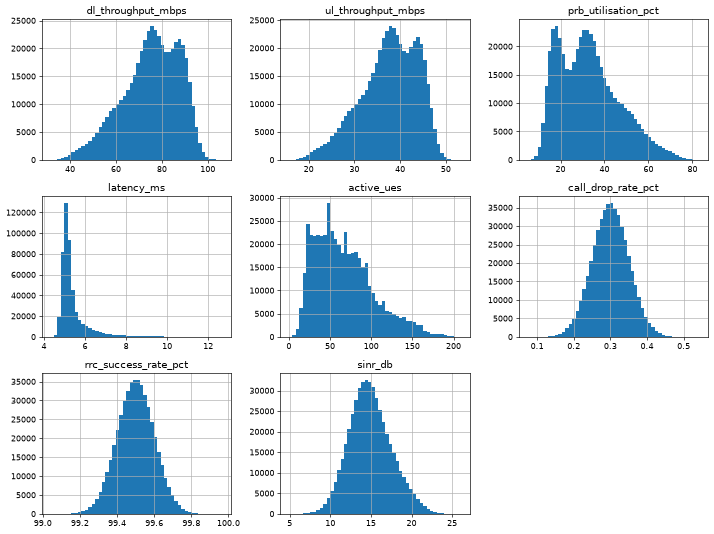

In [42]:
kpi_cols = df.columns[2:]

axes = df[kpi_cols].hist(bins=50, figsize=(12, 9), layout=(3, 3))
plt.tight_layout()
plt.show()

### 5. Relationships between KPIs

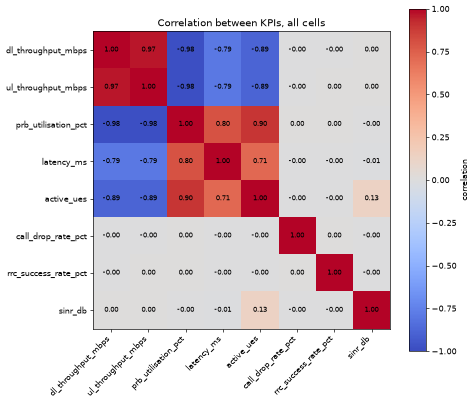

In [43]:
corr = df[kpi_cols].corr()

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(kpi_cols)), kpi_cols, rotation=45, ha="right")
ax.set_yticks(range(len(kpi_cols)), kpi_cols)
for i in range(len(kpi_cols)):
    for j in range(len(kpi_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, label="correlation")
ax.set_title("Correlation between KPIs, all cells")
fig.tight_layout()
plt.show()

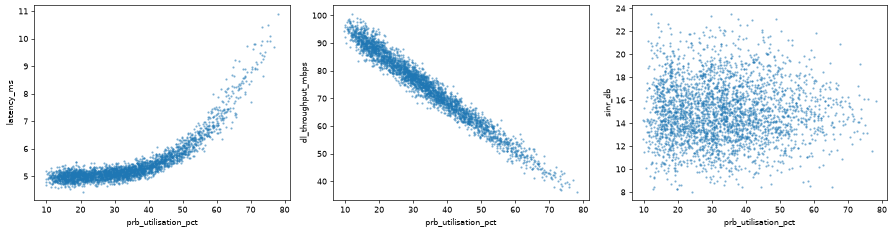

In [44]:
sample = df.sample(3000, random_state=0)
pairs = [
    ("prb_utilisation_pct", "latency_ms"),
    ("prb_utilisation_pct", "dl_throughput_mbps"),
    ("prb_utilisation_pct", "sinr_db"),
]

fig, axes = plt.subplots(1, len(pairs), figsize=(15, 4))
for ax, (x, y) in zip(axes, pairs, strict=True):
    ax.scatter(sample[x], sample[y], s=3, alpha=0.4)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
fig.tight_layout()
plt.show()

### 6. Difference between cells

In [45]:
df.groupby("cell_id")[["prb_utilisation_pct", "active_ues", "sinr_db"]].mean().round(1)

,prb_utilisation_pct,active_ues,sinr_db
cell_id,,,
site-a/cell-001,37.1,58.2,14.4
site-a/cell-002,30.8,76.1,19.4
site-a/cell-003,32.5,78.3,14.6
site-a/cell-004,28.9,44.6,12.6
site-b/cell-001,29.8,75.4,13.9
site-b/cell-002,31.4,82.6,17.0
site-b/cell-003,38.2,64.7,14.3
site-b/cell-004,28.4,53.6,14.3
site-c/cell-001,35.5,78.9,16.9


In [46]:
within = df.groupby("cell_id")[["active_ues", "sinr_db"]].corr()
within.xs("active_ues", level=1)["sinr_db"].round(2)

cell_id
site-a/cell-001    0.01
site-a/cell-002    0.01
site-a/cell-003   -0.04
site-a/cell-004   -0.01
site-b/cell-001    0.00
site-b/cell-002   -0.09
site-b/cell-003    0.00
site-b/cell-004    0.04
site-c/cell-001    0.01
site-c/cell-002   -0.05
site-c/cell-003   -0.00
site-c/cell-004   -0.02
Name: sinr_db, dtype: float64

### 7. Summary

1. **Data is complete and correct:** 483,840 rows (12 cells × 28 days × 1 per minute), no missing values, no gaps and types are kept by Parquet
2. **Values are realistic:** All KPIs are inside or close to their expected ranges. The few values just outside (throughput > 100 Mbps, PRB > 80 %, 0 users at night) come from the two noise layers and are rare and not bugs
3. **Daily and weekly pattern matches the design:** Three weekday peaks (08:30, 13:00, 19:30, evening the largest) and one broad weekend peak.
4. **KPIs are consistent with each other:** Users, PRB, throughput and latency all follow the hidden load
5. **Call drop and RRC success are pure noise on normal data** As no overload is reached any real movement in them would stand out. 
6. **Known bug:** the load jumps ~6 PRB points at the weekday↔weekend midnight (Sat and Mon 00:00). Kept on purpose, to measure its effect on false alarms in later evaluation
7. **Consequences for the detectors:** PRB, latency and users are lopsided (not bell-shaped) so a simple z-score may over-flag busy evenings. Cells differ in level so data should be scaled per cell. The daily pattern means a "quiet" value can be normal at night but abnormal in the afternoon so time of day matters.